# Part 5b: what happens when the LIHTC clock runs out?

Part 5 could not score LIHTC, the largest block of expiring subsidized units (48 percent of those ending by 2035), because NHPD holds almost no LIHTC outcomes. The HUD LIHTC
database does: the allocating agency flags projects it **no longer monitors** for LIHTC compliance (`NONPROG`, 11,217 of 54,928 projects). The dictionary is explicit that this
does *not* show the project stopped being affordable, and that the flag was reported informally before 2012. So the outcome here is **leaving the monitoring list**, the observable
sign that restrictions are no longer being checked.

* **Sample:** projects allocated in 1990 or later (the 30-year regime) and placed in service in 1990 to 1995, observed in 2024 at ages 29 to 34 (7,315 projects). Projects placed later are
  scored as if they behave like these cohorts when they reach the same age.
* **Question:** what predicts leaving, and can that be projected to the projects whose 30-year clock ends in 2026 to 2035?

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import lihtc_exit as L
from viz import apply_style, SERIES, save_figure, SURFACE, MUTED, BASELINE, INK_2, dot, tile_map, SEQUENTIAL

apply_style()
pd.set_option("display.width", 220)
panel = pd.read_csv("data/processed/panel.csv", dtype={"state_fips": str})
abbr = panel.groupby("state_fips").state_abbr.first()
allp = pd.read_csv("data/interim/lihtc_projects.csv.gz", dtype={"state_fips": str})
p = L.load_projects()

## 1. An age cliff, and 15-year versus 30-year allocations

pis_year,1987.0,1988.0,1989.0,1990.0,1991.0,1992.0,1993.0,1994.0,1995.0,1996.0,...,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0
regime,,,,,,,,,,,,,,,,,,,,,
allocated 1990 or later (30-year),NaN,NaN,NaN,0.72,0.62,0.59,0.52,0.4,0.32,0.29,...,0.1,0.06,0.07,0.05,0.04,0.04,0.02,0.03,0.02,0.13
allocated before 1990 (15-year),0.76,0.75,0.8,0.79,0.84,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


C:\Users\erick\AppData\Local\Temp\ipykernel_22804\1779648136.py:15: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


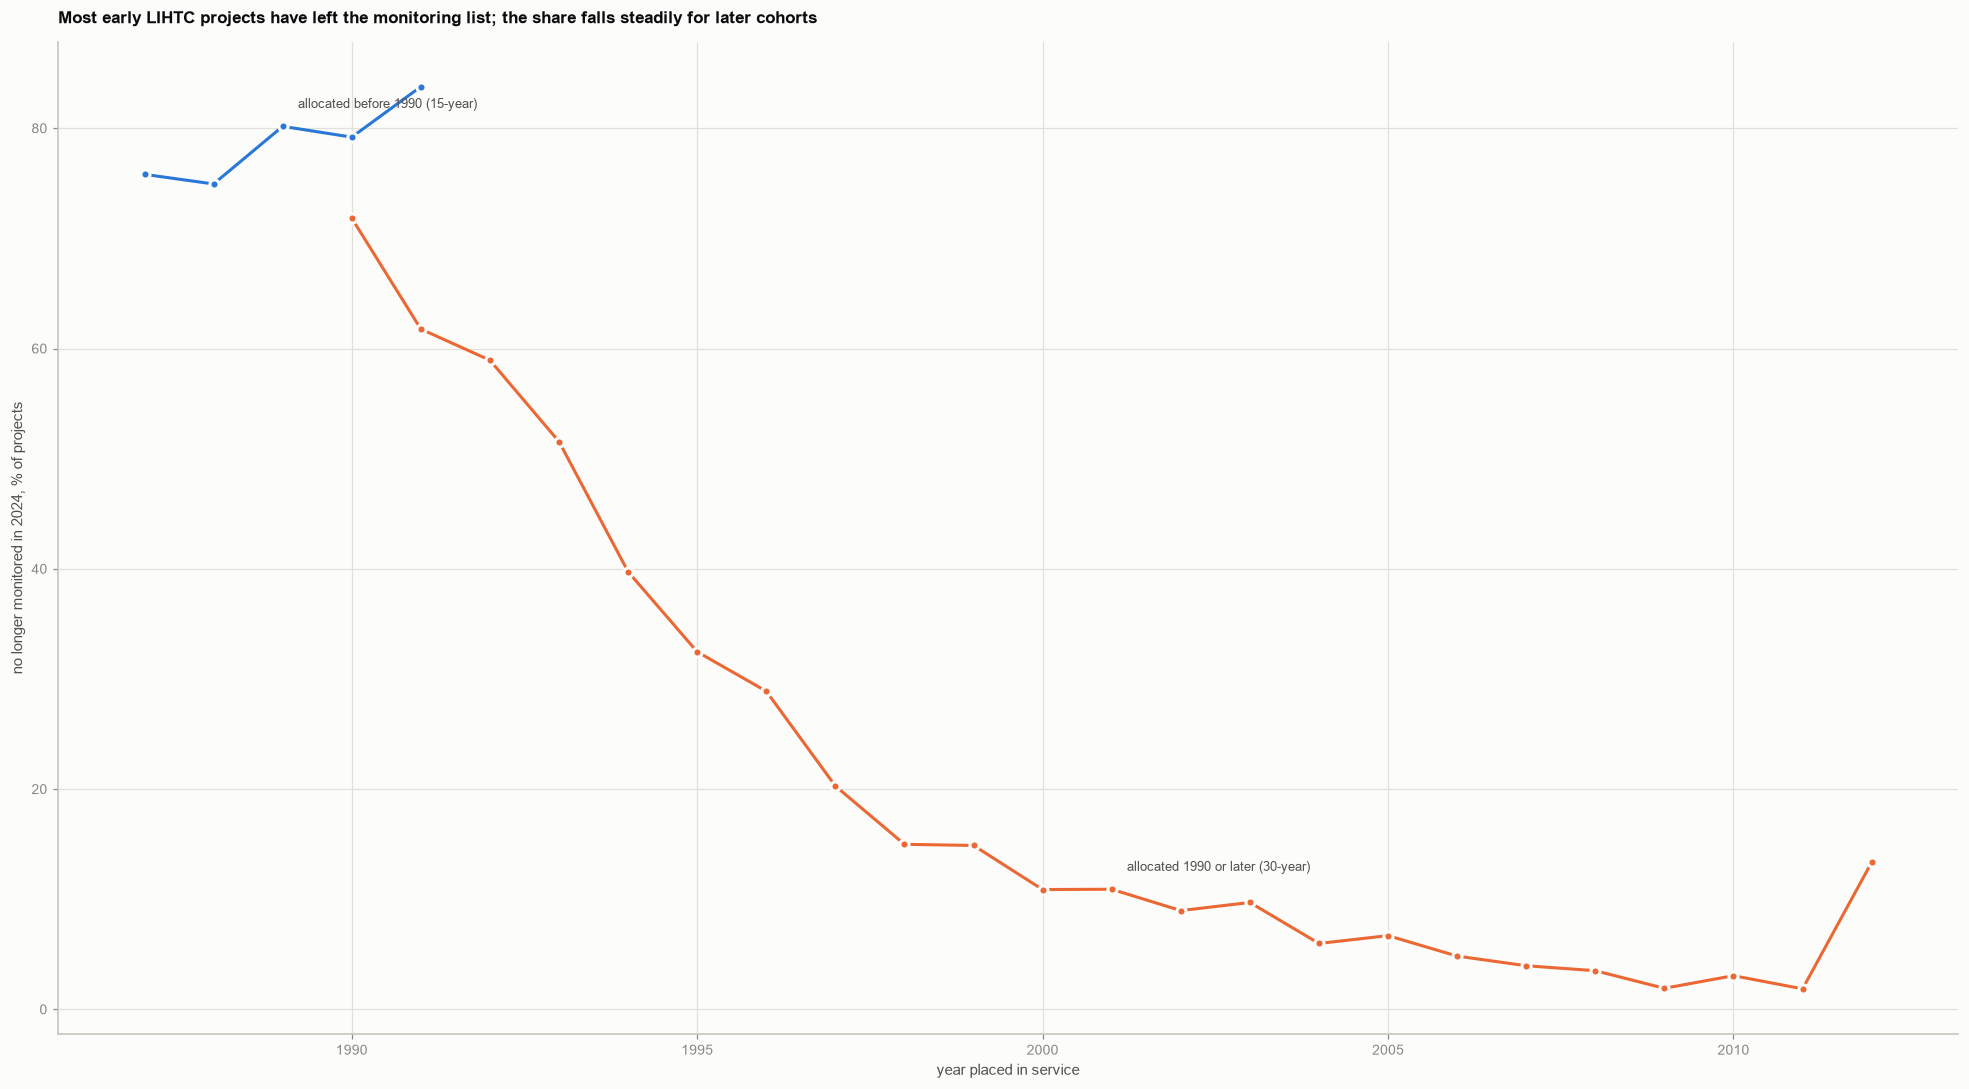

modeling sample: 7315 projects placed 1990 to 1995, 49% no longer monitored; by cohort: {1990: 0.72, 1991: 0.62, 1992: 0.59, 1993: 0.51, 1994: 0.39, 1995: 0.32}


In [2]:
g = allp[allp.pis_year.between(1987, 2012) & allp.alloc_pre1990.notna()].copy()
g["regime"] = np.where(g.alloc_pre1990 == 1, "allocated before 1990 (15-year)", "allocated 1990 or later (30-year)")
cur = g.groupby(["pis_year", "regime"]).left_monitoring.agg(["mean", "size"]).reset_index()
cur = cur[cur["size"] >= 30]
display(cur.pivot(index="pis_year", columns="regime", values="mean").round(2).T)
fig, ax = plt.subplots(figsize=(18, 10))
for reg, c in zip(sorted(cur.regime.unique()), (SERIES[1], SERIES[0])):
    d = cur[cur.regime == reg]
    ax.plot(d.pis_year, 100 * d["mean"], color=c)
    for x, v in zip(d.pis_year, d["mean"]):
        dot(ax, x, 100 * v, c)
    ax.annotate(reg, (d.pis_year.iloc[len(d) // 2], 100 * d["mean"].iloc[len(d) // 2]), xytext=(10, 12), textcoords="offset points", fontsize=8.5, color=INK_2)
ax.set_xlabel("year placed in service"); ax.set_ylabel("no longer monitored in 2024, % of projects")
ax.set_title("Most early LIHTC projects have left the monitoring list; the share falls steadily for later cohorts", fontsize=11, loc="left")
fig.tight_layout()
save_figure(fig, "52_exit_by_cohort", part="05_preservation")
plt.show()
n_ages = p[p.pis_year.between(1990, 1995)]
print(f"modeling sample: {len(n_ages)} projects placed 1990 to 1995, {n_ages.left_monitoring.mean():.0%} no longer monitored; by cohort:", n_ages.groupby('pis_year').left_monitoring.mean().round(2).to_dict())

## 2. What explains leaving: the project or the state?

Cohort split (train on 1990 to 1992, test on 1993 to 1995, ages 31 to 34 versus 29 to 31). Project characteristics: size, low-income share, sponsor type, credit type,
construction type, metro status, qualified tract, bond and basis boost, RHS and HOME financing, rental assistance, scattered site, target populations, and credit dollars per unit.
Then the same characteristics with the **leave-states-out** test: fit on some states, score the states never seen.

In [3]:
c = n_ages.copy()
c["log_units"] = np.log(c.n_units); c["alloc_pu"] = np.log1p(c.allocamt.fillna(0) / c.n_units)
chars = ["log_units", "li_share", "non_prof", "bond", "basis", "rhs", "home", "rentassist", "qct", "scattered_site_cd", "trgt_eld", "trgt_fam", "trgt_dis", "alloc_pu"]
cat = pd.get_dummies(c[["type", "credit", "metro"]].fillna(0).astype(int).astype(str), dtype=float)
Xc = pd.concat([c[chars].astype(float), cat], axis=1)
st = pd.get_dummies(c.state_fips, dtype=float)
y = c.left_monitoring.values
tr = (c.pis_year <= 1992).values; te = ~tr

def score(x, kind, train, test):
    xt, xe = x[train], x[test]
    if kind == "logit":
        med = xt.median(); xt, xe = xt.fillna(med), xe.fillna(med)
        m = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=5000))
    else:
        m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0)
    return roc_auc_score(y[test], m.fit(xt, y[train]).predict_proba(xe)[:, 1])

rows = []
for name, x in {"state only": st, "characteristics only": Xc, "state + characteristics": pd.concat([Xc, st], axis=1)}.items():
    for kind in ("logit", "boosting"):
        rows.append({"features": name, "model": kind, "cohort-split AUC": score(x, kind, tr, te)})
cs = pd.DataFrame(rows).pivot(index="features", columns="model", values="cohort-split AUC")
display(cs.round(3))
lso = []
for a, b in GroupKFold(5).split(Xc, y, c.state_fips):
    t = np.zeros(len(c), bool); t[a] = True; e = np.zeros(len(c), bool); e[b] = True
    lso.append(score(Xc, "logit", t, e))
print(f"characteristics only, leave-states-out (5 folds, logit): AUC {np.mean(lso):.2f} (folds {np.round(lso, 2).tolist()})")

model,boosting,logit
features,,
characteristics only,0.755,0.596
state + characteristics,0.803,0.778
state only,0.775,0.785


characteristics only, leave-states-out (5 folds, logit): AUC 0.52 (folds [0.62, 0.52, 0.48, 0.48, 0.52])


Characteristics alone carry little that travels across states. The state does. Some of the boosting score for characteristics comes from variables that proxy for the state
(credit dollars per unit, for instance); that is why the leave-states-out test is the one to read.

## 3. How much do states differ, and do the differences persist?

,1990-92,1993-95,1996-2000,2001-05
1990-92,1.00,0.79,0.60,0.43
1993-95,0.79,1.00,0.84,0.49
1996-2000,0.60,0.84,1.00,0.69
2001-05,0.43,0.49,0.69,1.00


cohort 1993-95, 44 states with 15 or more projects: range 0% (CT) to 99% (MD); median 36%


C:\Users\erick\AppData\Local\Temp\ipykernel_22804\938302618.py:16: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


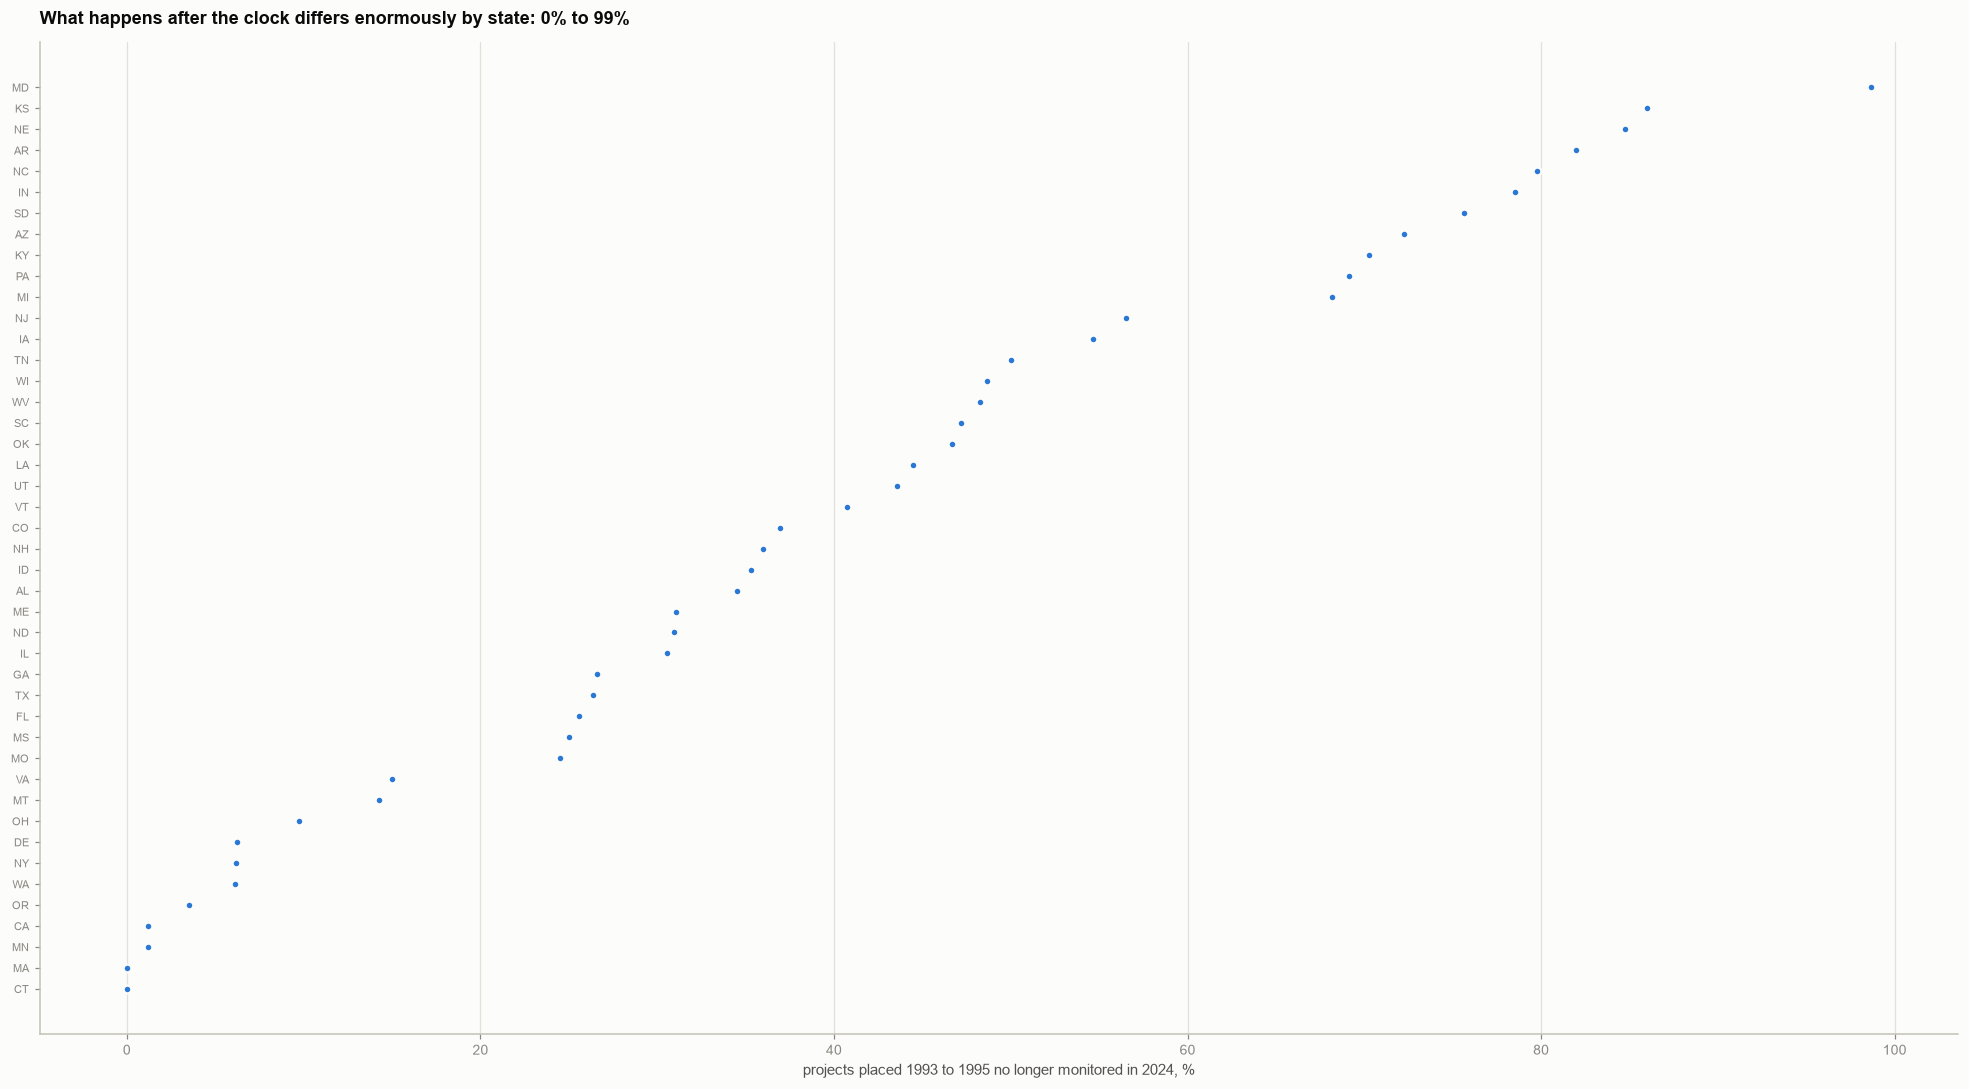

In [4]:
coh = {"1990-92": (1990, 1992), "1993-95": (1993, 1995), "1996-2000": (1996, 2000), "2001-05": (2001, 2005)}
R = {}
for k, (a, b) in coh.items():
    q = p[p.pis_year.between(a, b)].groupby("state_fips").left_monitoring.agg(["mean", "size"])
    R[k] = q["mean"].where(q["size"] >= 15)
R = pd.DataFrame(R)
display(R.corr(method="spearman").round(2))
sb = R["1993-95"].dropna().sort_values()
print(f"cohort 1993-95, {len(sb)} states with 15 or more projects: range {sb.min():.0%} ({abbr[sb.index[0]]}) to {sb.max():.0%} ({abbr[sb.index[-1]]}); median {sb.median():.0%}")
fig, ax = plt.subplots(figsize=(18, 10))
ys = np.arange(len(sb))
ax.scatter(100 * sb.values, ys, s=26, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.set_yticks(ys, [abbr[s] for s in sb.index], fontsize=7.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("projects placed 1993 to 1995 no longer monitored in 2024, %")
ax.set_title(f"What happens after the clock differs enormously by state: {100 * sb.min():.0f}% to {100 * sb.max():.0f}%", fontsize=11.5, loc="left")
fig.tight_layout()
save_figure(fig, "52_exit_by_state", part="05_preservation")
plt.show()

## 4. The model and its out-of-sample test

`StateLogit`: a state effect plus a cohort trend, penalized so that small states are pulled toward the national level (`C` is the inverse penalty). Tested without peeking: train on 1990-92, predict 1993-95
at the project level (AUC), and at the state level compare the weighted error of the predicted exit rate with a model that has only the national trend.

In [5]:
rows = []
for C in (0.1, 0.3, 1.0, 3.0):
    r = L.cohort_split_eval(n_ages, C)
    rows.append({"C": C, "project AUC": r["auc"], "state error": r["state_mae"], "state error, national trend only": r["state_mae_national_trend"], "state correlation": r["state_corr"], "mean predicted": r["mean_pred"], "mean observed": r["mean_obs"]})
ev = pd.DataFrame(rows).set_index("C")
display(ev.round(3))
CHOSEN = 0.3
r = L.cohort_split_eval(n_ages, CHOSEN)
print(f"chosen C = {CHOSEN}: AUC {r['auc']:.2f}; state-level error {r['state_mae']:.3f} against {r['state_mae_national_trend']:.3f} for the national trend (a {100 * (1 - r['state_mae'] / r['state_mae_national_trend']):.0f} percent reduction); "
      f"predicted mean {r['mean_pred']:.3f} against observed {r['mean_obs']:.3f}")
ev.to_csv("outputs/tables/lihtc_exit_model_eval.csv")

,project AUC,state error,"state error, national trend only",state correlation,mean predicted,mean observed
C,,,,,,
0.1,0.793,0.139,0.254,0.757,0.468,0.405
0.3,0.797,0.134,0.253,0.799,0.476,0.405
1.0,0.797,0.138,0.253,0.812,0.484,0.405
3.0,0.795,0.143,0.253,0.810,0.489,0.405


chosen C = 0.3: AUC 0.80; state-level error 0.134 against 0.253 for the national trend (a 47 percent reduction); predicted mean 0.476 against observed 0.405


## 5. Application: the projects whose 30-year clock ends 2026 to 2035

Fit on all of 1990 to 1995, then for every project placed in 1996 to 2005 predict the share that will have left the monitoring list by the age of the cohorts in the training sample (about 31, so 2027 to 2036).
Projects that have already left are counted as such; the expected additional units are the monitored units times the further share that is expected to leave, per state and cohort. Bootstrap ranges refit the model on resampled projects.

In [6]:
final = L.StateLogit(CHOSEN).fit(n_ages)
fut = L.project_future(p, final)
cell = fut.groupby(["state_fips", "pis_year"]).agg(p31=("p31", "first"), observed=("left_monitoring", "mean"), projects=("hud_id", "size"))
fut = fut.join(cell.rename(columns={"observed": "obs_cell"})[["obs_cell"]], on=["state_fips", "pis_year"])
fut["remaining_share"] = ((fut.p31 - fut.obs_cell) / (1 - fut.obs_cell)).clip(lower=0, upper=1)
mon = fut[fut.left_monitoring == 0].copy()
mon["expected_units"] = mon.n_units * mon.remaining_share
total_units = mon.n_units.sum(); expected = mon.expected_units.sum()
print(f"{len(mon)} projects placed 1996 to 2005 are still monitored ({total_units:,.0f} units); expected to leave by about age 31: {expected:,.0f} units ({expected / total_units:.0%})")

# the cohort test over-predicted the level (mean predicted above observed), so a calibration-adjusted variant scales the predicted shares by observed / predicted
scale = r["mean_obs"] / r["mean_pred"]
adj = (mon.n_units * (((fut.loc[mon.index, "p31"] * scale) - mon.obs_cell) / (1 - mon.obs_cell)).clip(lower=0, upper=1)).sum()
print(f"calibration-adjusted (shares scaled by {scale:.2f}): {adj:,.0f} units ({adj / total_units:.0%})  ->  planning range {adj:,.0f} to {expected:,.0f}")

mon["expected_units_adj"] = mon.n_units * ((((fut.loc[mon.index, "p31"] * scale) - mon.obs_cell) / (1 - mon.obs_cell)).clip(lower=0, upper=1))

rng = np.random.default_rng(0)
boot = []
for _ in range(200):
    bs = n_ages.sample(len(n_ages), replace=True, random_state=int(rng.integers(1e9)))
    m = L.StateLogit(CHOSEN, states=final.states).fit(bs)
    pb = pd.Series(m.predict(mon, pis_year=L.TREND_CENTER), index=mon.index)
    rem = ((pb - mon.obs_cell) / (1 - mon.obs_cell)).clip(lower=0, upper=1)
    boot.append((mon.n_units * rem).groupby(mon.state_fips).sum())
B = pd.concat(boot, axis=1)
stt = pd.DataFrame({"state": B.index.map(abbr), "monitored_units_placed_1996_2005": mon.groupby("state_fips").n_units.sum(), "expected_units_leaving": mon.groupby("state_fips").expected_units.sum(), "expected_units_leaving_adj": mon.groupby("state_fips").expected_units_adj.sum(),
                    "low": B.quantile(0.05, axis=1), "high": B.quantile(0.95, axis=1)}, index=B.index)
stt["share_leaving_pct"] = 100 * stt.expected_units_leaving / stt.monitored_units_placed_1996_2005
tot = B.sum()
print(f"national total, 90 percent bootstrap range (sampling uncertainty only): {tot.quantile(0.05):,.0f} to {tot.quantile(0.95):,.0f}")
stt.to_csv("outputs/tables/lihtc_exit_state.csv")
display(stt.sort_values("expected_units_leaving", ascending=False).head(8).round(0))
display(stt.sort_values("share_leaving_pct", ascending=False).head(5).round(1))
display(stt.sort_values("share_leaving_pct").head(5).round(1))

13007 projects placed 1996 to 2005 are still monitored (1,002,236 units); expected to leave by about age 31: 296,639 units (30%)
calibration-adjusted (shares scaled by 0.85): 235,693 units (24%)  ->  planning range 235,693 to 296,639


national total, 90 percent bootstrap range (sampling uncertainty only): 285,948 to 307,114


,state,monitored_units_placed_1996_2005,expected_units_leaving,expected_units_leaving_adj,low,high,share_leaving_pct
state_fips,,,,,,,
12,FL,89969.0,27041.0,21979.0,20351.0,32005.0,30.0
37,NC,23424.0,18342.0,14524.0,17726.0,19102.0,78.0
48,TX,77570.0,18250.0,14847.0,14948.0,21658.0,24.0
26,MI,27309.0,17693.0,13962.0,16170.0,19379.0,65.0
24,MD,19410.0,17608.0,14724.0,17203.0,17904.0,91.0
39,OH,50119.0,12151.0,10272.0,10478.0,13956.0,24.0
42,PA,14500.0,11653.0,9616.0,11199.0,12150.0,80.0
55,WI,16982.0,11205.0,9320.0,10277.0,11932.0,66.0


,state,monitored_units_placed_1996_2005,expected_units_leaving,expected_units_leaving_adj,low,high,share_leaving_pct
state_fips,,,,,,,
24,MD,19410.0,17608.2,14724.2,17202.6,17903.7,90.7
31,NE,4029.0,3295.6,2620.8,3094.9,3472.3,81.8
42,PA,14500.0,11653.3,9615.9,11199.3,12149.7,80.4
37,NC,23424.0,18342.4,14524.3,17726.0,19102.5,78.3
18,IN,14223.0,10002.4,7017.3,9123.7,10868.0,70.3


,state,monitored_units_placed_1996_2005,expected_units_leaving,expected_units_leaving_adj,low,high,share_leaving_pct
state_fips,,,,,,,
06,CA,130534.0,7844.0,6549.1,6171.3,9778.2,6.0
27,MN,17446.0,1392.1,1167.1,1113.8,1790.0,8.0
25,MA,23072.0,1977.3,1682.9,1711.9,2286.4,8.6
30,MT,2371.0,215.9,146.8,88.5,428.6,9.1
28,MS,10322.0,967.7,733.1,594.9,1345.5,9.4


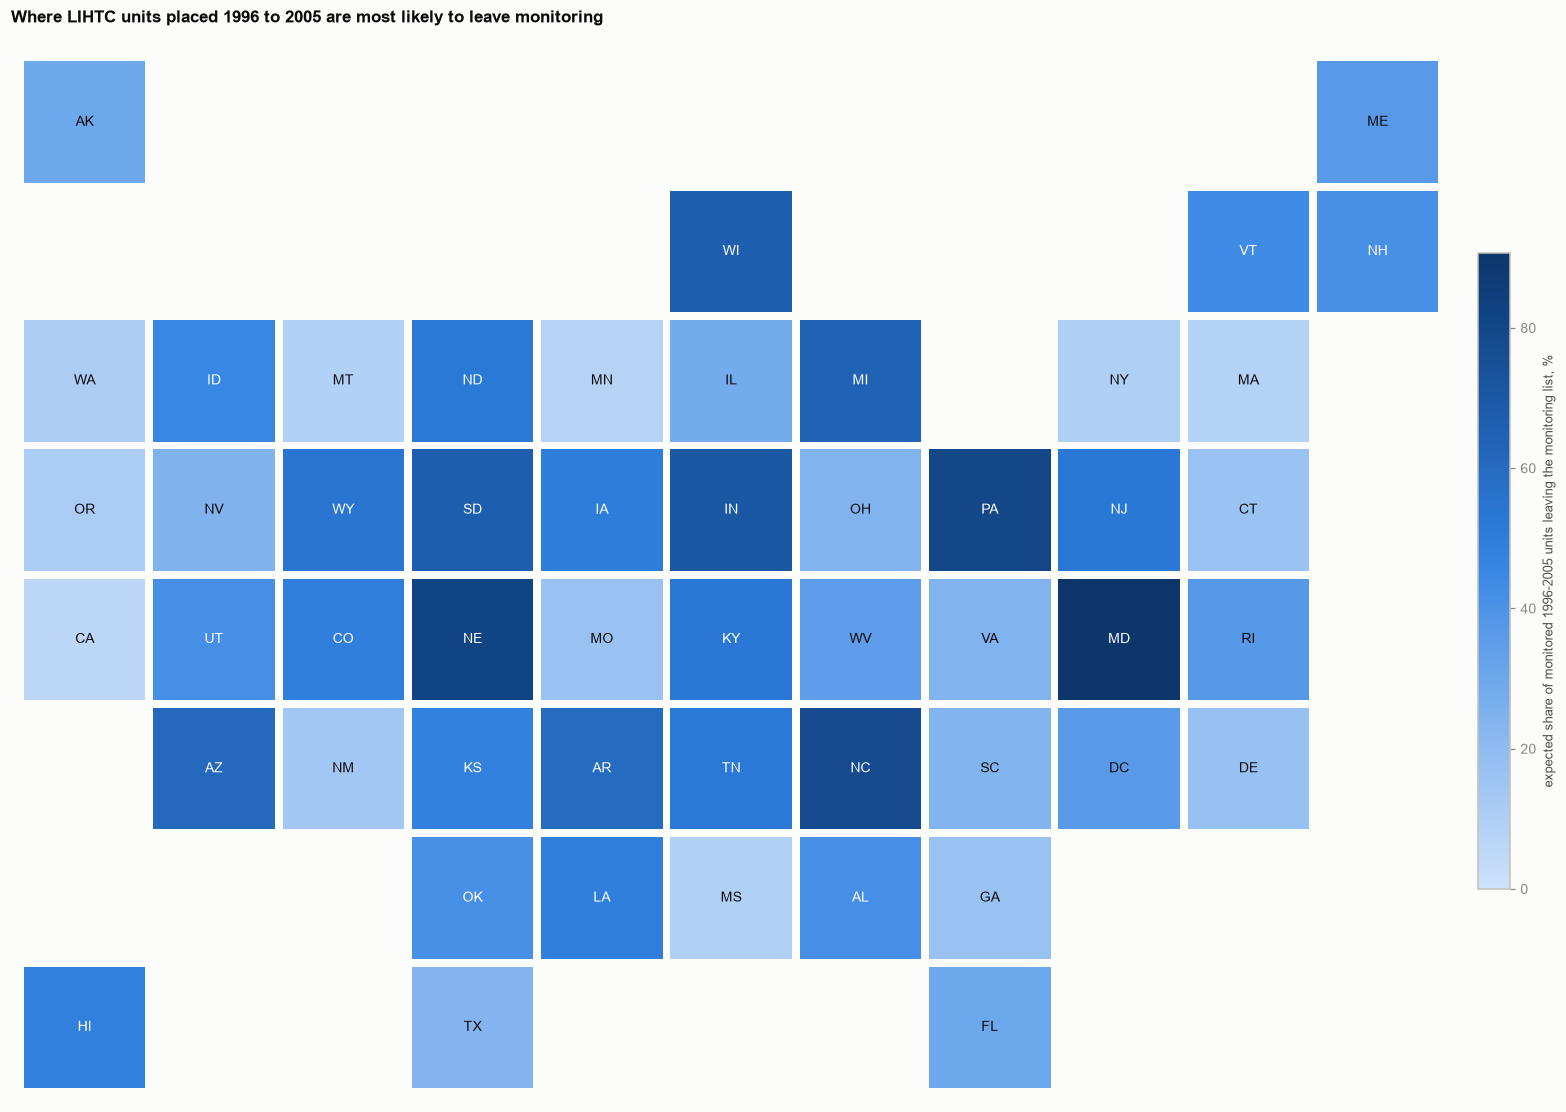

In [7]:
fig, ax = plt.subplots(figsize=(18, 10))
v = stt.set_index("state").share_leaving_pct
m = tile_map(ax, v, cmap=SEQUENTIAL, vmin=0, vmax=v.max())
cb = fig.colorbar(m, ax=ax, shrink=0.6, pad=0.01); cb.set_label("expected share of monitored 1996-2005 units leaving the monitoring list, %", fontsize=8.5)
ax.set_title("Where LIHTC units placed 1996 to 2005 are most likely to leave monitoring", fontsize=11, loc="left")
save_figure(fig, "52_lihtc_exit_map", part="05_preservation")
plt.show()

## Findings

**The outcome is usable, with one clear limit.** 11,217 of 54,928 projects (20 percent) are flagged as no longer monitored. That is the observable end of the LIHTC clock, not proof that the units stopped being
affordable (the dictionary says so, and the flag was reported informally before 2012). Everything below is about leaving the monitoring list. The 2012 placement cohort has an unexplained spike (13 percent) and is not used.

**An age cliff.** Of projects allocated before 1990 (15-year commitments) 75 to 84 percent have left monitoring. Among 30-year allocations the share falls from 72 percent for 1990 placements to 62, 59, 52, 40, and 32 percent
for 1991 to 1995, to 15 percent for 1998 and about 3 percent for 2010: the older the cohort, the more have left.

**It is the state, not the project.** On a cohort split (train 1990 to 1992, test 1993 to 1995) state alone ranks projects with an AUC of 0.79. Project characteristics (size, low-income share, sponsor, credit and construction type, location,
financing, target population) reach 0.60 with a logit and 0.76 with boosting, but fitted on some states and scored on states never seen they have an AUC of 0.52, no better than chance, and they add nothing once the state is in (0.78 to 0.80). State
rates for projects placed 1993 to 1995 run from 0 percent (Connecticut) to 99 percent (Maryland), median 36 percent. State differences persist across adjacent cohorts (rank correlation 0.79, 0.84, 0.69) and fade with distance (0.43 between
1990-92 and 2001-05). Whether this is state policy (extended-use rules, preservation programs) or state reporting practice cannot be separated with these data, and it matters for how to read the numbers.

**The model.** A state-effects logit with a cohort trend, tested without peeking: project-level AUC 0.80, state-level error 0.134 against 0.253 for a national trend alone (47 percent lower), state correlation 0.80. It over-predicts the level (mean predicted 0.476 against
0.405 observed), so a calibration-adjusted version is reported beside the unadjusted one.

**Application.** 13,007 projects placed 1996 to 2005 are still monitored, with 1,002,236 units (this matches the 1.0 million units in Section 13 whose estimated 30-year clock ends by 2035). If they behave like the 1990 to 1995 cohorts at the same age, about
**236,000 to 297,000 units (24 to 30 percent) will have left the monitoring list by the time each cohort reaches about 31 years (2027 to 2036)**. The bootstrap range (286,000 to 307,000) covers sampling error only, not this assumption. Largest totals: Florida (27,000, 30 percent of its
monitored units), North Carolina (18,000, 78 percent), Texas (18,000, 24), Michigan (18,000, 65), Maryland (18,000, 91), Ohio (12,000), Pennsylvania (12,000, 80), Wisconsin (11,000, 66). Highest shares: Maryland 91, Nebraska 82, Pennsylvania 80, North Carolina 78, Indiana 70. Lowest: California 6, Minnesota 8,
Massachusetts 9, Montana 9, Mississippi 9.

**Reading it for action.** States where most projects drop off the list soon after the first compliance period are where monitoring, and so any chance to negotiate extension or preservation, ends earliest. If the state pattern is reporting, the numbers overstate real losses; if it is policy, it points at what low-exit states
(California, Minnesota, Massachusetts) do differently. Either way, the state agency is the unit that matters, not the property type, so a property-level targeting model for LIHTC is not supported by these data.

**Caveats.** Cohort extrapolation (projects placed 2001 to 2005 are furthest from the training cohorts and least certain); no information on what happened to affordability after monitoring ended; 7,315 training projects; the state effect mixes policy and reporting. Tables: `outputs/tables/lihtc_exit_model_eval.csv`, `lihtc_exit_state.csv`.